# 05 — Score field cells against every dataset

Three steps:
1. Link each res-13 field cell to the dataset cells it overlaps, once per dataset resolution and independent of the date.
2. Join the links to the dataset layer for the raw rows, `h3_field_measures_perc`.
3. Reduce the raw rows to an overlap-weighted value per field cell, `h3_field_measures_weighted`, and to plain and edge-weighted scores per field, `h3_field_measures_blended`.

In [0]:
%run ./config_nb

geobrix 0.6.0: one wheel per runtime (+env5 / +env6); SQL functions register through databricks.labs.gbx.register(spark); the Python API is rasterx / gridx / vectorx. See https://databrickslabs.github.io/geobrix/docs/migration-0-6
geobrix: JVM level unavailable: Spark Connect session (Serverless); using the Python level (48 functions)
geobrix: SQL expression level unavailable: 5 functions (gbx_bng_cellarea, gbx_bng_eastnorthasbng, gbx_quadbin_distance, ...) need a SQL function wrapper, and SQL functions are unavailable here; using the Python level


... EARTHDATA_TOKEN loaded from geospatial_docs.vapor_eyes.earthdata_token


True

DataFrame[]

H3PX_DIR = /Volumes/geospatial_docs/h3_pixels_crop_yield/data/h3-pixels-crop-yield


... view helpers: show_cells, show_tile (gated by INTERACTIVE_PLOTS)


## Links: simple cells and straddlers

H3 is not nested: the logical parent of a cell (`h3_toparent`) does not always hold it.
A cell that its parent holds gets one link at 100%.
Every other cell, a true straddler or a cell that sits outside its logical parent, gets an exact overlap with each cell of the parent's k-ring (`LINK_K`).
`field_attr_perc` is the share of the field cell's area inside the dataset cell, with both cells cut in EPSG:5070.
The containment test is planar in lon/lat while the cut is in EPSG:5070; the difference is negligible at these cell sizes.
The raw shares go to `h3_field_cell_links_raw`.

In [0]:
def links_sql(cells_sql, k):
    """Links of the field cells in cells_sql (field_h3_cellid, field_h3_res, attr_h3_res): one 100% link where the
    logical parent holds the cell, else an exact overlap with each cell of the parent's k-ring."""
    return f"""
  WITH p AS (SELECT c.*, h3_toparent(c.field_h3_cellid, c.attr_h3_res) AS parent,
                    st_setsrid(st_geomfromwkb(h3_boundaryaswkb(c.field_h3_cellid)), 4326) AS hc
             FROM ({cells_sql}) c),
  s AS (SELECT p.*, st_contains(st_setsrid(st_geomfromwkb(h3_boundaryaswkb(parent)), 4326), hc) AS simple FROM p),
  x AS (SELECT s.field_h3_cellid, s.field_h3_res, s.attr_h3_res, k AS attr_h3_cellid, st_transform(s.hc, 5070) AS hc_m,
               st_transform(st_setsrid(st_geomfromwkb(h3_boundaryaswkb(k)), 4326), 5070) AS hs_m
        FROM s LATERAL VIEW explode(h3_kring(s.parent, {k})) e AS k WHERE NOT s.simple),
  -- The overlap is cut in EPSG:5070, so the pieces of a field cell tile it there and their areas sum to its area.
  -- An OUTER generator output is computed once per pair (a WHERE on the expression, or the filter Spark infers for
  -- a plain generator, would compute it again).
  o AS (SELECT x.field_h3_cellid, x.field_h3_res, x.attr_h3_res, x.attr_h3_cellid, perc
        FROM x LATERAL VIEW OUTER explode(array(100.0D * st_area(st_intersection(hs_m, hc_m)) / st_area(hc_m))) v AS perc
        WHERE st_intersects(hs_m, hc_m))
  SELECT field_h3_cellid, field_h3_res, attr_h3_res, parent AS attr_h3_cellid, 100.0D AS field_attr_perc,
         false AS is_straddle FROM s WHERE simple
  UNION ALL
  SELECT field_h3_cellid, field_h3_res, attr_h3_res, attr_h3_cellid, perc AS field_attr_perc, true AS is_straddle
  FROM o WHERE perc > 0"""


cells_sql = """SELECT fc.*, r.attr_h3_res FROM (SELECT DISTINCT field_h3_cellid, field_h3_res FROM h3_field_cells) fc
               CROSS JOIN (SELECT DISTINCT attr_h3_res FROM dataset_resolutions) r"""
# Spread the field cells over the cluster before the cut, the costly step.
spread = f"SELECT /*+ REPARTITION({FANOUT}, field_h3_cellid) */ * FROM ({cells_sql})"
raw = spark.sql(links_sql(spread, LINK_K)).repartition(FANOUT, "attr_h3_res", "field_h3_cellid")
h3_field_cell_links_raw = _persist(raw, "h3_field_cell_links_raw", cluster_by=["attr_h3_res", "field_h3_cellid"])

... table h3_field_cell_links_raw exists (skip; FORCE_REBUILD=False)


A field cell whose shares do not sum to 100 is cut again against the ring one step wider, and any share gained there replaces its links.
Neighbouring H3 cells can place a shared boundary vertex a fraction of a millimetre apart where an edge crosses an icosahedron face, which leaves a sliver gap between them.
So each straddler's shares are rescaled to sum to 100, after a check that the raw gap stays below 0.01 percentage points, and the rescaled links go to `h3_field_cell_links`.

In [0]:
# Field cells whose shares do not sum to 100 (or that got no link), cut again against the ring one step wider: a
# share gained there is a true miss, and the wider rows replace that cell's rows.
off = spark.sql(f"""
  SELECT c.field_h3_cellid, c.field_h3_res, c.attr_h3_res, coalesce(l.raw_sum, 0.0D) AS raw_sum FROM ({cells_sql}) c
  LEFT JOIN (SELECT field_h3_cellid, attr_h3_res, sum(field_attr_perc) AS raw_sum FROM h3_field_cell_links_raw GROUP BY 1, 2) l
    ON l.field_h3_cellid = c.field_h3_cellid AND l.attr_h3_res = c.attr_h3_res
  WHERE abs(coalesce(l.raw_sum, 0.0D) - 100) > 1e-6""").collect()
spark.createDataFrame(off, "field_h3_cellid bigint, field_h3_res int, attr_h3_res int, raw_sum double") \
    .createOrReplaceTempView("_links_off")
link_schema = ("field_h3_cellid bigint, field_h3_res int, attr_h3_res int, attr_h3_cellid bigint, field_attr_perc double, "
               "is_straddle boolean")
wide = spark.sql(links_sql("SELECT field_h3_cellid, field_h3_res, attr_h3_res FROM _links_off", LINK_K + 1)).collect()
spark.createDataFrame(wide, link_schema).createOrReplaceTempView("_links_wide")
chk = spark.sql("""
  SELECT o.field_h3_cellid, o.attr_h3_res, o.raw_sum, coalesce(w.wide_sum, 0.0D) AS wide_sum FROM _links_off o
  LEFT JOIN (SELECT field_h3_cellid, attr_h3_res, sum(field_attr_perc) AS wide_sum FROM _links_wide GROUP BY 1, 2) w
    ON w.field_h3_cellid = o.field_h3_cellid AND w.attr_h3_res = o.attr_h3_res""").collect()
miss = [(r["field_h3_cellid"], r["attr_h3_res"]) for r in chk if r["wide_sum"] - r["raw_sum"] > 1e-9]
spark.createDataFrame(miss, "field_h3_cellid bigint, attr_h3_res int").createOrReplaceTempView("_links_miss")
base = "field_h3_cellid, field_h3_res, attr_h3_res, attr_h3_cellid, field_attr_perc, is_straddle"
spark.sql(f"""
  SELECT {base} FROM h3_field_cell_links_raw LEFT ANTI JOIN _links_miss USING (field_h3_cellid, attr_h3_res)
  UNION ALL
  SELECT {base} FROM _links_wide LEFT SEMI JOIN _links_miss USING (field_h3_cellid, attr_h3_res)""").createOrReplaceTempView("_links_fixed")

# The remaining gap is H3's: rescale each straddler's shares to sum to 100, after checking the raw gap stays small.
gap = spark.sql("""
  WITH t AS (SELECT field_h3_cellid, attr_h3_res, sum(field_attr_perc) AS raw_sum, max(CAST(is_straddle AS INT)) AS straddle
             FROM _links_fixed GROUP BY 1, 2)
  SELECT attr_h3_res, sum(straddle) AS rescaled, max(abs(raw_sum - 100)) AS worst_raw_gap FROM t GROUP BY 1 ORDER BY 1""").collect()
for r in gap:
    res = r["attr_h3_res"]
    print(f"res {res}: {sum(c['attr_h3_res'] == res for c in chk)} cells off 100 by > 1e-6 checked against ring "
          f"{LINK_K + 1}, {sum(m[1] == res for m in miss)} true misses; {r['rescaled']:,} straddlers rescaled; "
          f"worst raw gap {r['worst_raw_gap']:.2e} percentage points")
assert all(r["worst_raw_gap"] <= 0.01 for r in gap), "a field cell's raw shares miss 100 by more than 0.01 percentage points"
links = spark.sql("""
  SELECT field_h3_cellid, field_h3_res, attr_h3_res, attr_h3_cellid,
         CASE WHEN is_straddle
              THEN field_attr_perc * 100.0D / sum(field_attr_perc) OVER (PARTITION BY field_h3_cellid, attr_h3_res)
              ELSE field_attr_perc END AS field_attr_perc,
         is_straddle
  FROM _links_fixed""").repartition(FANOUT, "attr_h3_res", "field_h3_cellid")
h3_field_cell_links = _persist(links, "h3_field_cell_links", cluster_by=["attr_h3_res", "attr_h3_cellid"])

res 6: 0 cells off 100 by > 1e-6 checked against ring 2, 0 true misses; 1,250,864 straddlers rescaled; worst raw gap 2.20e-09 percentage points
res 7: 165 cells off 100 by > 1e-6 checked against ring 2, 0 true misses; 1,255,283 straddlers rescaled; worst raw gap 1.32e-03 percentage points
res 12: 0 cells off 100 by > 1e-6 checked against ring 2, 0 true misses; 15,906,580 straddlers rescaled; worst raw gap 1.13e-09 percentage points
... table h3_field_cell_links exists (skip; FORCE_REBUILD=False)


Per resolution: the field cells, the share that took the exact path (`straddle_share`), and the worst error of the summed shares against 100%.
Every field cell of `h3_field_cells` must keep a link at every resolution.

In [0]:
s = spark.sql("""
  WITH t AS (SELECT field_h3_cellid, attr_h3_res, sum(field_attr_perc) AS total, max(CAST(is_straddle AS INT)) AS straddle
             FROM h3_field_cell_links GROUP BY 1, 2)
  SELECT attr_h3_res, count(*) AS cells, avg(straddle) AS straddle_share, max(abs(total - 100)) AS worst
  FROM t GROUP BY 1 ORDER BY 1""")
display(s)
rows = s.collect()
assert all(r["worst"] <= 1e-9 for r in rows), "a field cell's shares do not sum to 100"
n_cells = spark.sql("SELECT count(DISTINCT field_h3_cellid) AS n FROM h3_field_cells").first()["n"]
res_list = [r["attr_h3_res"] for r in spark.sql("SELECT DISTINCT attr_h3_res FROM dataset_resolutions").collect()]
assert {r["attr_h3_res"]: r["cells"] for r in rows} == {res: n_cells for res in res_list}, \
    f"a field cell has no link at some resolution ({n_cells:,} field cells)"

attr_h3_res,cells,straddle_share,worst
6,18557719,0.06740397351635727,2.842170943040401e-14
7,18557719,0.06764209545364923,2.842170943040401e-14
12,18557719,0.8571409018532935,2.842170943040401e-14


## Raw rows (`h3_field_measures_perc`)

A key join of the links to the dataset layer on (`attr_h3_res`, `attr_h3_cellid`), for the dates in each field's season.
Only field cells at least `SETBACK_M` inside the edge are kept.
A simple cell has one row per dataset date, a straddler one row per dataset cell it overlaps and date.
For a coarse dataset a field cell's percentages sum to 100 on each date; HLS keeps no row for a clouded dataset cell, so there they sum to the clear share.

In [0]:
perc = spark.sql(f"""
  SELECT c.field_id, l.field_h3_res, l.field_h3_cellid, l.field_attr_perc, m.dataset, m.collect_date,
         l.attr_h3_res, l.attr_h3_cellid, m.attr_name, m.attr_measure, c.edge_dist_m, c.centroid_dist_m
  FROM h3_field_cell_links l
  JOIN h3_dataset_measures m ON m.attr_h3_res = l.attr_h3_res AND m.attr_h3_cellid = l.attr_h3_cellid
  JOIN h3_field_cells c ON c.field_h3_cellid = l.field_h3_cellid AND year(m.collect_date) = c.season
  WHERE c.edge_dist_m >= {SETBACK_M}""").repartition(FANOUT, "field_id")
h3_field_measures_perc = _persist(perc, "h3_field_measures_perc", cluster_by=["field_id", "dataset"])

... table h3_field_measures_perc exists (skip; FORCE_REBUILD=False)


## Weighted per field cell, blended per field

The weighted value of a field cell is the overlap-weighted mean over its valid dataset cells; `perc_valid` is the share that was valid.
The blended scores per field are the plain mean of the weighted values and the edge-weighted mean, with `w = min(1, d / D)` (`d` is `edge_dist_m`, `D` is `EDGE_WEIGHT_D_M`).
`valid_cell_frac` is the share of the field's kept cells with a value; for HLS it is the clear share of the field on that scene.
NDVI also gets the centroid baseline's rule: `ndvi_aug_mean` is the mean over the August scenes of the per-scene field score.

In [0]:
def weighted_sql(perc_view):
    return f"""
      SELECT field_id, field_h3_res, field_h3_cellid, dataset, collect_date, attr_name,
             try_divide(sum(CASE WHEN attr_measure IS NOT NULL THEN field_attr_perc * attr_measure END),
                        sum(CASE WHEN attr_measure IS NOT NULL THEN field_attr_perc END)) AS attr_measure,
             sum(CASE WHEN attr_measure IS NOT NULL THEN field_attr_perc END) AS perc_valid,
             count(DISTINCT attr_h3_cellid) AS n_attr_cells, first(edge_dist_m) AS edge_dist_m,
             first(centroid_dist_m) AS centroid_dist_m
      FROM {perc_view} GROUP BY field_id, field_h3_res, field_h3_cellid, dataset, collect_date, attr_name"""


def blended_sql(weighted_view, kept_view):
    """Per field: the scores and valid_cell_frac, the share of the field's kept cells (kept_view: field_id,
    season, n_kept) with a value. HLS keeps no row for a clouded cell, so the weighted rows alone cannot give it."""
    w = f"least(1.0D, edge_dist_m / {float(EDGE_WEIGHT_D_M)})"
    return f"""
      WITH b0 AS (
        SELECT field_id, year(collect_date) AS season, dataset, collect_date, attr_name,
               avg(attr_measure) AS score_unweighted,
               try_divide(sum(CASE WHEN attr_measure IS NOT NULL THEN {w} * attr_measure END),
                          sum(CASE WHEN attr_measure IS NOT NULL THEN {w} END)) AS score_edge_weighted,
               count(attr_measure) AS n_cells
        FROM {weighted_view} GROUP BY field_id, year(collect_date), dataset, collect_date, attr_name),
      b AS (SELECT b0.*, b0.n_cells / k.n_kept AS valid_cell_frac FROM b0 JOIN {kept_view} k USING (field_id, season)),
      ndvi AS (
        SELECT field_id, season, 'hls' AS dataset, make_date(season, 8, 1) AS collect_date, 'ndvi_aug_mean' AS attr_name,
               avg(score_unweighted) AS score_unweighted, avg(score_edge_weighted) AS score_edge_weighted,
               count(score_unweighted) AS n_cells, avg(CASE WHEN score_unweighted IS NOT NULL THEN valid_cell_frac END) AS valid_cell_frac
        FROM b WHERE attr_name = 'ndvi' GROUP BY field_id, season)
      SELECT * FROM b UNION ALL SELECT * FROM ndvi"""


spark.table("h3_field_measures_perc").createOrReplaceTempView("_perc")
h3_field_measures_weighted = _persist(spark.sql(weighted_sql("_perc")), "h3_field_measures_weighted",
                                      cluster_by=["field_id", "dataset"])
h3_field_measures_weighted.createOrReplaceTempView("_weighted")
spark.sql(f"""SELECT field_id, season, count(*) AS n_kept FROM h3_field_cells WHERE edge_dist_m >= {SETBACK_M}
              GROUP BY field_id, season""").createOrReplaceTempView("_kept")
h3_field_measures_blended = _persist(spark.sql(blended_sql("_weighted", "_kept")), "h3_field_measures_blended",
                                     cluster_by=["field_id"])

... table h3_field_measures_weighted exists (skip; FORCE_REBUILD=False)
... table h3_field_measures_blended exists (skip; FORCE_REBUILD=False)


## Checks

Two synthetic fields with a fully clouded and a clear scene pin the NULL handling, for a coarse layer (NULL rows) and for HLS (no rows).
On the real tables, a field cell's shares sum to 100% per dataset, date and attribute (at most 100% for HLS), and no blended score is NaN.

In [0]:
# Two synthetic fields, each with a fully clouded and a clear August scene.
# f1, a 'complete' layer: every dataset cell of the clouded scene is NULL. Expected: NULL measure and perc_valid (never
# NaN or an error) and a blended row with no score. f2, a 'sparse' layer like HLS: the clouded scene leaves no rows, so
# it has no blended row, and one of the field's 3 kept cells is clouded on the clear scene too. For both,
# ndvi_aug_mean averages only the clear scene, and valid_cell_frac = n_cells / kept cells.
spark.createDataFrame([
    ("f1", 13, 1, 100.0, "hls_l30", "2023-08-05", 12, 11, "ndvi", None, 15.0, 40.0),
    ("f1", 13, 2, 100.0, "hls_l30", "2023-08-05", 12, 12, "ndvi", None, 25.0, 30.0),
    ("f1", 13, 1, 100.0, "hls_l30", "2023-08-13", 12, 11, "ndvi", 0.8, 15.0, 40.0),
    ("f1", 13, 2, 100.0, "hls_l30", "2023-08-13", 12, 12, "ndvi", 0.6, 25.0, 30.0),
    ("f2", 13, 3, 100.0, "hls_l30", "2023-08-13", 12, 21, "ndvi", 0.8, 15.0, 40.0),
    ("f2", 13, 4, 100.0, "hls_l30", "2023-08-13", 12, 22, "ndvi", 0.6, 25.0, 30.0),
], "field_id string, field_h3_res int, field_h3_cellid bigint, field_attr_perc double, dataset string, collect_date string, "
   "attr_h3_res int, attr_h3_cellid bigint, attr_name string, attr_measure double, edge_dist_m double, centroid_dist_m double") \
    .withColumn("collect_date", F.to_date("collect_date")).createOrReplaceTempView("_t_perc")
spark.createDataFrame([("f1", 2023, 2), ("f2", 2023, 3)], "field_id string, season int, n_kept bigint") \
    .createOrReplaceTempView("_t_kept")
spark.sql(weighted_sql("_t_perc")).createOrReplaceTempView("_t_w")
wv = {(str(r["collect_date"]), r["field_h3_cellid"]): r for r in spark.table("_t_w").collect()}
assert wv[("2023-08-05", 1)]["attr_measure"] is None and wv[("2023-08-05", 1)]["perc_valid"] is None
bl = {(r["field_id"], r["attr_name"], str(r["collect_date"])): r for r in spark.sql(blended_sql("_t_w", "_t_kept")).collect()}
assert bl[("f1", "ndvi", "2023-08-05")]["score_unweighted"] is None and bl[("f1", "ndvi", "2023-08-05")]["n_cells"] == 0
assert bl[("f1", "ndvi", "2023-08-05")]["valid_cell_frac"] == 0 and bl[("f1", "ndvi", "2023-08-13")]["valid_cell_frac"] == 1
assert ("f2", "ndvi", "2023-08-05") not in bl and abs(bl[("f2", "ndvi", "2023-08-13")]["valid_cell_frac"] - 2 / 3) < 1e-12
for f in ("f1", "f2"):
    aug = bl[(f, "ndvi_aug_mean", "2023-08-01")]
    assert aug["n_cells"] == 1 and abs(aug["score_unweighted"] - 0.7) < 1e-12
    assert abs(aug["score_edge_weighted"] - (0.5 * 0.8 + 0.8333333333333334 * 0.6) / (0.5 + 0.8333333333333334)) < 1e-12
    assert abs(aug["valid_cell_frac"] - bl[(f, "ndvi", "2023-08-13")]["valid_cell_frac"]) < 1e-12
print("synthetic clouded scenes: all checks passed")

synthetic clouded scenes: all checks passed


In [0]:
# A 'complete' dataset sums to 100% per field cell, date and attribute. A 'sparse' one (HLS, GRID_COVERAGE) keeps no
# row for a clouded dataset cell, so its sum is the clear share of the field cell: at most 100%.
sparse = ", ".join(f"'{d}'" for d, c in GRID_COVERAGE.items() if c == "sparse") or "''"
p = {r["sparse"]: r for r in spark.sql(f"""
  SELECT dataset IN ({sparse}) AS sparse, count(*) AS groups, max(abs(t - 100)) AS worst, max(t) AS top FROM (
    SELECT field_h3_cellid, dataset, collect_date, attr_name, sum(field_attr_perc) AS t
    FROM h3_field_measures_perc GROUP BY 1, 2, 3, 4) GROUP BY 1""").collect()}
print({("sparse" if k else "complete"): {c: v[c] for c in ("groups", "worst", "top")} for k, v in p.items()})
assert p[False]["worst"] <= 1e-6
assert True not in p or p[True]["top"] <= 100 + 1e-6
n = spark.sql("SELECT count(*) AS c FROM h3_field_measures_blended WHERE isnan(score_unweighted) OR isnan(score_edge_weighted)").first()
assert n["c"] == 0
print(f"h3_field_measures_perc: {spark.table('h3_field_measures_perc').count():,} rows")

{'complete': {'groups': 489086247, 'worst': 2.842170943040401e-14, 'top': 100.00000000000003}, 'sparse': {'groups': 157477965, 'worst': 99.99999995696896, 'top': 100.00000000000003}}
h3_field_measures_perc: 782,383,772 rows


## Payoff

The July precipitation anomaly per field, unweighted against edge-weighted, and a map of the field scores: the August NDVI mean when HLS is staged, else the July anomaly.
The July anomaly runs from about -67 to +24 mm per field, and the two scores sit on the equal-score line: a res-7 dataset cell (about 5 km²) is much larger than a field, so most fields lie in one or two cells and the edge weight barely moves the score.
The map shows the August NDVI mean per field, mostly 0.8 to 0.9 (5th to 95th percentile 0.78 to 0.90) with a few low fields; the blank middle has no corn polys.

August NDVI mean per field: 5th to 95th percentile 0.78 to 0.90


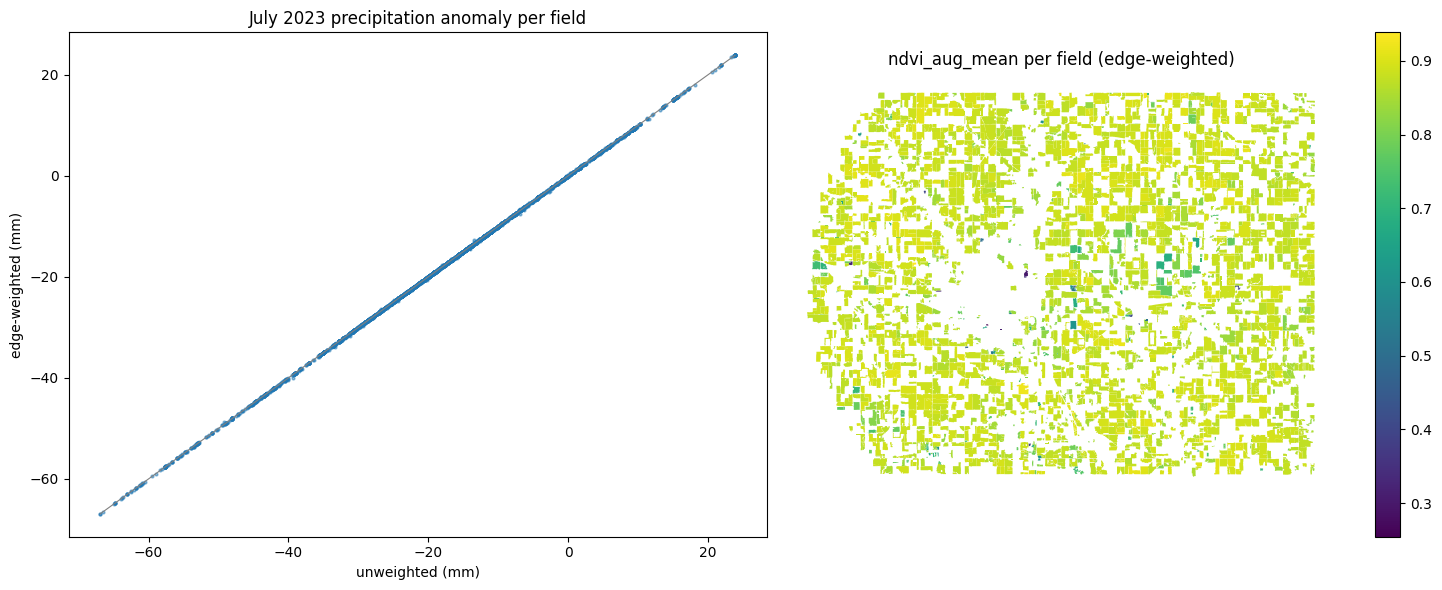

In [0]:
import geopandas as gpd
import matplotlib.pyplot as plt
import shapely

july = f"{SEASONS[0]}-07-01"
sc = spark.sql(f"""SELECT score_unweighted, score_edge_weighted FROM h3_field_measures_blended
                   WHERE attr_name = 'precip_anom_mm' AND collect_date = '{july}'""").toPandas()
map_attr, map_date = ("ndvi_aug_mean", f"{SEASONS[0]}-08-01") if EARTHDATA_READY else ("precip_anom_mm", july)
fp = spark.sql(f"""SELECT st_asbinary(p.field_poly) AS wkb, b.score_edge_weighted AS score
                   FROM h3_field_measures_blended b JOIN field_polys p USING (field_id, season)
                   WHERE b.attr_name = '{map_attr}' AND b.collect_date = '{map_date}'""").toPandas()
if EARTHDATA_READY:
    p5, p95 = fp["score"].quantile([0.05, 0.95])
    print(f"August NDVI mean per field: 5th to 95th percentile {p5:.2f} to {p95:.2f}")
gdf = gpd.GeoDataFrame({"score": fp["score"]}, geometry=shapely.from_wkb(fp["wkb"].map(bytes)), crs=4326)

fig, (a0, a1) = plt.subplots(1, 2, figsize=(15, 6))
a0.scatter(sc["score_unweighted"], sc["score_edge_weighted"], s=4, alpha=0.5)
lo, hi = sc.min().min(), sc.max().max()
a0.plot([lo, hi], [lo, hi], color="grey", linewidth=0.8)  # equal scores
a0.set_xlabel("unweighted (mm)")
a0.set_ylabel("edge-weighted (mm)")
a0.set_title(f"July {SEASONS[0]} precipitation anomaly per field")
gdf.plot(column="score", ax=a1, legend=True, cmap="viridis", linewidth=0)
a1.set_title(f"{map_attr} per field (edge-weighted)")
a1.set_axis_off()
plt.tight_layout()
plt.show()